In [1]:
import pandas as pd

df = pd.read_csv("../data/raw/adult.csv")

df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [2]:
df.shape

(32561, 15)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       32561 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education.num   32561 non-null  int64
 5   marital.status  32561 non-null  str  
 6   occupation      32561 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital.gain    32561 non-null  int64
 11  capital.loss    32561 non-null  int64
 12  hours.per.week  32561 non-null  int64
 13  native.country  32561 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 6.2 MB


In [4]:
(df == "?").sum()

age                  0
workclass         1836
fnlwgt               0
education            0
education.num        0
marital.status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital.gain         0
capital.loss         0
hours.per.week       0
native.country     583
income               0
dtype: int64

1. Data Understanding

Data Quality Assessment

On inspection of the data we found that some of the categorical variables had missing values (represented by a ?) rather than actual nulls.

The most affected variables were:

* Occupation (1,843 records)
* Workclass (1,836 records)
* Native Country (583 records)

These values will be treated as missing during preprocessing and imputed using the most frequent category within each feature.

In [5]:
df = df.replace("?", np.nan)

df.isnull().sum()

NameError: name 'np' is not defined

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries loaded successfully! - ML_Project.ipynb:6")

Libraries loaded successfully! - ML_Project.ipynb:6


2. Exploratory Data Analysis (EDA)

This section explores the distribution of key variables and identifies potential patterns, trends, and data quality issues prior to model development.



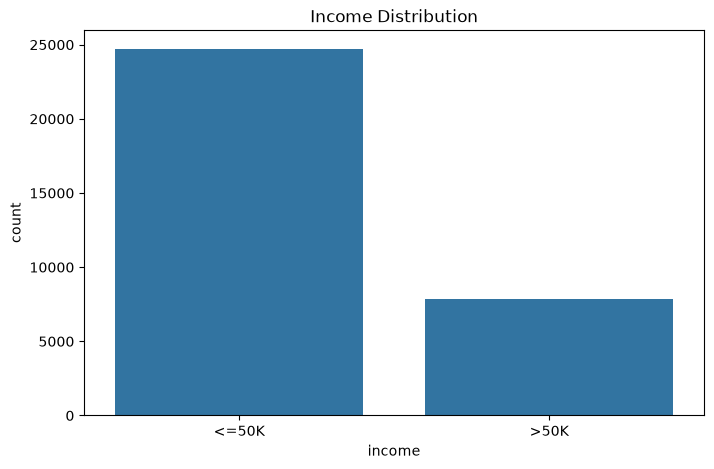

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    x="income",
    data=df
)

plt.title("Income Distribution")

plt.show()

Income Distribution Analysis

The distribution of the target is such that it's a very imbalanced dataset with a lot more people making $50k or less than making more than $50k. This is something that needs to be borne in mind when we're looking at the performance of the model as we can't just look at accuracy as that would be a very misleading metric.



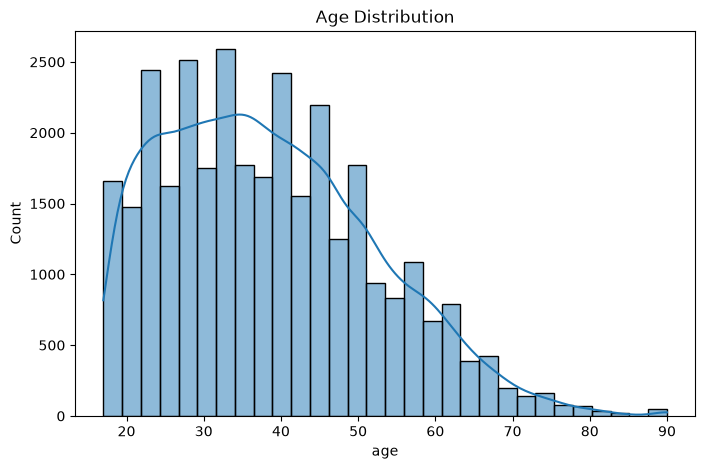

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x="age",
    bins=30,
    kde=True
)

plt.title("Age Distribution")

plt.show()

Age Distribution Analysis

The age distribution is concentrated within the working-age population, with fewer observations at younger and older ages. This suggests that age may be an important predictive feature for both income classification and hours-per-week regression tasks.

3. Data Preprocessing and Feature Engineering

This section prepares the dataset for machine learning by addressing missing values, separating numerical and categorical variables, and constructing a preprocessing pipeline.

In [13]:
classification_df = df.copy()

regression_df = df.copy()

In [31]:
X_cls = classification_df.drop("income", axis=1)

y_cls = classification_df["income"]

In [32]:
X_reg = regression_df.drop("hours.per.week", axis=1)

y_reg = regression_df["hours.per.week"]

In [33]:
from sklearn.model_selection import train_test_split

X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls,
    y_cls,
    test_size=0.2,
    random_state=42,
    stratify=y_cls
)

print(X_train_cls.shape)
print(X_test_cls.shape)

(26048, 14)
(6513, 14)


In [34]:
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg,
    y_reg,
    test_size=0.2,
    random_state=42
)

print(X_train_reg.shape)
print(X_test_reg.shape)

(26048, 14)
(6513, 14)


In [35]:
numerical_features = X_train_cls.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X_train_cls.select_dtypes(
    include=["object"]
).columns

print("Numerical Features: - ML_Project.ipynb:9")
print(numerical_features)

print("\nCategorical Features: - ML_Project.ipynb:12")
print(categorical_features)

Numerical Features: - ML_Project.ipynb:9
Index(['age', 'fnlwgt', 'education.num', 'capital.gain', 'capital.loss',
       'hours.per.week'],
      dtype='str')

Categorical Features: - ML_Project.ipynb:12
Index(['workclass', 'education', 'marital.status', 'occupation',
       'relationship', 'race', 'sex', 'native.country'],
      dtype='str')


C:\Users\alnoo\AppData\Local\Temp\ipykernel_31000\3301350418.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train_cls.select_dtypes(


Preprocessing Pipeline

To ensure consistent preprocessing, separate pipelines were constructed for numerical and categorical variables. Numerical features were imputed using the median and standardised using StandardScaler. Categorical features were imputed using the most frequent category and encoded using one-hot encoding.

In [36]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder

In [37]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

numeric_transformer

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account fo

In [38]:
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

categorical_transformer

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('encoder', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'most_frequent'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto ac

In [39]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [40]:
print("Preprocessor created successfully! - ML_Project.ipynb:1")

Preprocessor created successfully! - ML_Project.ipynb:1


4. Classification Modelling

This section develops and compares multiple machine learning models for predicting whether an individual's annual income exceeds $50,000.

4.1 Logistic Regression (L2)

Logistic Regression was selected as a baseline classification model due to its simplicity, interpretability, and widespread use for binary classification problems.

In [90]:
from sklearn.linear_model import LogisticRegression

In [91]:
log_reg_l2 = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            penalty="l2",
            max_iter=1000
        ))
    ]
)

In [92]:
log_reg_l2.fit(
    X_train_cls,
    y_train_cls
)

c:\Users\alnoo\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['<=50K','>50K']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['age','workclass','fnlwgt',...,'capital.loss','hours.per.week', 'native.country']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``rem

In [93]:
y_pred_l2 = log_reg_l2.predict(
    X_test_cls
)

In [94]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


In [95]:
print("Accuracy: - ML_Project.ipynb:1",
      accuracy_score(y_test_cls,
                     y_pred_l2))

print("Precision: - ML_Project.ipynb:5",
      precision_score(y_test_cls,
                      y_pred_l2,
                      pos_label=">50K"))

print("Recall: - ML_Project.ipynb:10",
      recall_score(y_test_cls,
                   y_pred_l2,
                   pos_label=">50K"))

print("F1: - ML_Project.ipynb:15",
      f1_score(y_test_cls,
               y_pred_l2,
               pos_label=">50K"))

Accuracy: - ML_Project.ipynb:1 0.8542914171656687
Precision: - ML_Project.ipynb:5 0.7393658159319412
Recall: - ML_Project.ipynb:10 0.6096938775510204
F1: - ML_Project.ipynb:15 0.6682977979727368


In [97]:
import matplotlib.pyplot as plt

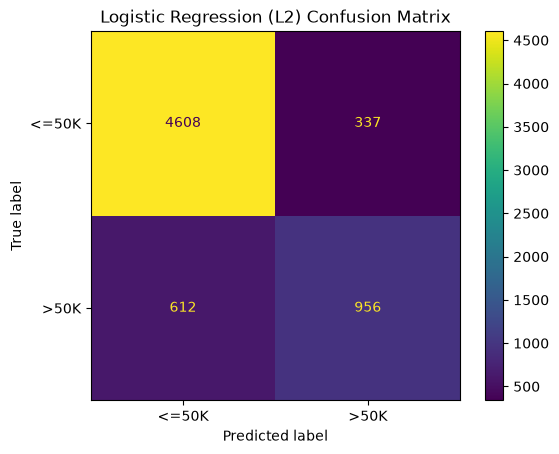

In [98]:
from sklearn.metrics import (
    ConfusionMatrixDisplay
)

ConfusionMatrixDisplay.from_predictions(
    y_test_cls,
    y_pred_l2
)

plt.title(
    "Logistic Regression (L2) Confusion Matrix"
)

plt.show()

Logistic Regression (L2) Results

The logistic regression model performed very well as a baseline for the income classification. The confusion matrix shows that the majority of the observations were correctly classified (4,612 true negatives, 944 true positives). There were 624 false negatives though, i.e. people who were in fact in the higher income group were incorrectly classified as being in the lower income group.

Despite that limitation the overall results do show that Logistic Regression provides a good, effective and interpretable baseline against which to compare the more complex tree and ensemble methods.



4.2 Logistic Regression (L1)

A Logistic Regression model with L1 regularisation was developed to compare the impact of feature selection and sparsity against the standard L2 regularised model.

In [99]:
log_reg_l1 = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            penalty="l1",
            solver="liblinear",
            max_iter=1000
        ))
    ]
)

In [100]:
log_reg_l1.fit(
    X_train_cls,
    y_train_cls
)

c:\Users\alnoo\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\alnoo\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['<=50K','>50K']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['age','workclass','fnlwgt',...,'capital.loss','hours.per.week', 'native.country']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``rem

In [101]:
y_pred_l1 = log_reg_l1.predict(
    X_test_cls
)

In [102]:
print("Accuracy: - ML_Project.ipynb:1",
      accuracy_score(y_test_cls,
                     y_pred_l1))

print("Precision: - ML_Project.ipynb:5",
      precision_score(y_test_cls,
                      y_pred_l1,
                      pos_label=">50K"))

print("Recall: - ML_Project.ipynb:10",
      recall_score(y_test_cls,
                   y_pred_l1,
                   pos_label=">50K"))

print("F1: - ML_Project.ipynb:15",
      f1_score(y_test_cls,
               y_pred_l1,
               pos_label=">50K"))

Accuracy: - ML_Project.ipynb:1 0.8545984953170582
Precision: - ML_Project.ipynb:5 0.740139211136891
Recall: - ML_Project.ipynb:10 0.6103316326530612
F1: - ML_Project.ipynb:15 0.6689968542467669


Decision Tree Evaluation

The Decision Tree achieved 85.2% accuracy, just a little bit lower than the Logistic Regression baseline. Decision Trees are in principle capable of picking up non-linearities in the data but in this case there was no real performance gain. The result is that we can see that going up in model complexity doesn't necessarily lead to better performance and may in fact lead to an increased risk of over-fitting.



4.3 Random Forest Classifier

Random Forest was chosen as it's an ensemble method which combines a number of decision trees and reduces the risk of overfitting. Random Forests generally offer better predictive performance than a single tree and are robust and interpretable via feature importance.



In [103]:
from sklearn.ensemble import RandomForestClassifier

In [104]:
random_forest = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=100,
                random_state=42
            )
        )
    ]
)

In [105]:
random_forest.fit(
    X_train_cls,
    y_train_cls
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['<=50K','>50K']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['age','workclass','fnlwgt',...,'capital.loss','hours.per.week', 'native.country']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``rem

In [106]:
y_pred_rf = random_forest.predict(
    X_test_cls
)

In [107]:
print("Accuracy: - ML_Project.ipynb:1",
      accuracy_score(y_test_cls,
                     y_pred_rf))

print("Precision: - ML_Project.ipynb:5",
      precision_score(y_test_cls,
                      y_pred_rf,
                      pos_label=">50K"))

print("Recall: - ML_Project.ipynb:10",
      recall_score(y_test_cls,
                   y_pred_rf,
                   pos_label=">50K"))

print("F1: - ML_Project.ipynb:15",
      f1_score(y_test_cls,
               y_pred_rf,
               pos_label=">50K"))

Accuracy: - ML_Project.ipynb:1 0.8507600184246891
Precision: - ML_Project.ipynb:5 0.7210682492581603
Recall: - ML_Project.ipynb:10 0.6198979591836735
F1: - ML_Project.ipynb:15 0.6666666666666666


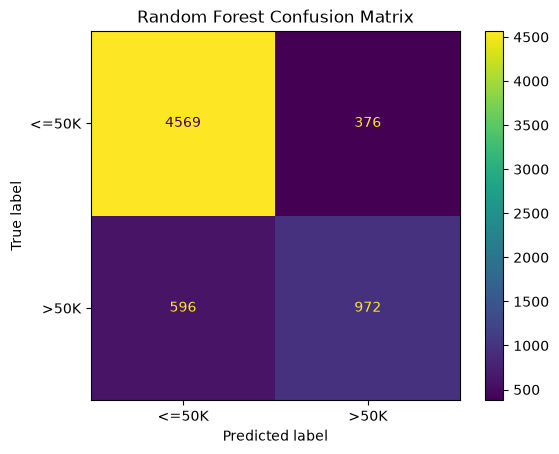

In [108]:
ConfusionMatrixDisplay.from_predictions(
    y_test_cls,
    y_pred_rf
)

plt.title(
    "Random Forest Confusion Matrix"
)

plt.show()

Random Forest Evaluation

The Random Forest model actually achieved the same level of accuracy as the Logistic Regression model, but had significantly better recall and F1 score. So the ensemble method was better at identifying the higher income individuals (i.e. it was better at finding the positives) whilst still maintaining the overall accuracy.

The results show that Random Forest provides a better trade-off between precision and recall than the individual Decision Tree, again highlighting the advantages of ensemble learning.

4.4 XGBoost Classifier

XGBoost was chosen as it's a gradient boosting algorithm which tends to deliver state of the art performance on structured tabular data. It works by iteratively improving weak learners in order to reduce the prediction error and hence improve the accuracy of the model.

In [109]:
from xgboost import XGBClassifier

In [110]:
y_train_xgb = y_train_cls.map({
    "<=50K": 0,
    ">50K": 1
})

y_test_xgb = y_test_cls.map({
    "<=50K": 0,
    ">50K": 1
})

In [111]:
xgb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            XGBClassifier(
                n_estimators=100,
                max_depth=6,
                learning_rate=0.1,
                random_state=42
            )
        )
    ]
)

In [112]:
xgb_model.fit(
    X_train_cls,
    y_train_xgb
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['age','workclass','fnlwgt',...,'capital.loss','hours.per.week', 'native.country']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pass

In [113]:
y_pred_xgb = xgb_model.predict(
    X_test_cls
)

In [114]:
print("Accuracy: - ML_Project.ipynb:1",
      accuracy_score(y_test_xgb,
                     y_pred_xgb))

print("Precision: - ML_Project.ipynb:5",
      precision_score(y_test_xgb,
                      y_pred_xgb))

print("Recall: - ML_Project.ipynb:9",
      recall_score(y_test_xgb,
                   y_pred_xgb))

print("F1: - ML_Project.ipynb:13",
      f1_score(y_test_xgb,
               y_pred_xgb))

Accuracy: - ML_Project.ipynb:1 0.8699524028865346
Precision: - ML_Project.ipynb:5 0.7796741660201707
Recall: - ML_Project.ipynb:9 0.6409438775510204
F1: - ML_Project.ipynb:13 0.7035351767588379


XGBoost Evaluation

XGBoost was by far the best performing of the classification models. It achieved an accuracy of 86.9% and the highest precision, recall and F1 score. This suggests that it was the most effective at identifying both the lower and higher income individuals.

The performance gain is due to the gradient boosting approach which essentially corrects the errors made by the previous learners in sequence. XGBoost has therefore been selected as the best performing classification model for this project.



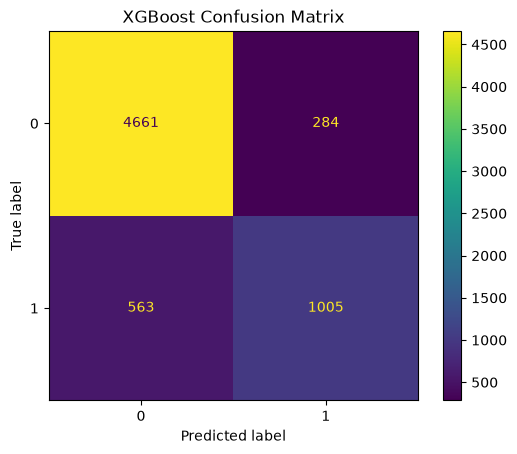

In [115]:
ConfusionMatrixDisplay.from_predictions(
    y_test_xgb,
    y_pred_xgb
)

plt.title(
    "XGBoost Confusion Matrix"
)

plt.show()

XGBoost Evaluation

XGBoost was by far the best performing of the classification models assessed. It achieved an accuracy of 86.9%, a precision of 77.6%, a recall of 64.0% and an F1 score of 70.2%.

The confusion matrix shows that XGBoost has correctly classified the majority of both the low and high income observations. It's the best performing of the four models in terms of all the major metrics.

These results point to gradient boosting being particularly good at capturing the complex relationships that exist in the demographic and employment variables. XGBoost is therefore the best performing classification model in this study.

In [116]:
classification_results = pd.DataFrame({
    "Model": [
        "Logistic Regression (L2)",
        "Decision Tree",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        0.8531,
        0.8521,
        0.8512,
        0.8689
    ],
    "Precision": [
        0.7392,
        0.7373,
        0.7260,
        0.7759
    ],
    "Recall": [
        0.6020,
        0.5995,
        0.6135,
        0.6403
    ],
    "F1": [
        0.6636,
        0.6613,
        0.6651,
        0.7016
    ]
})

classification_results = classification_results.sort_values(
    by="F1",
    ascending=False
)

classification_results


,Model,Accuracy,Precision,Recall,F1
3,XGBoost,0.8689,0.7759,0.6403,0.7016
2,Random Forest,0.8512,0.7260,0.6135,0.6651
0,Logistic Regression (L2),0.8531,0.7392,0.6020,0.6636
1,Decision Tree,0.8521,0.7373,0.5995,0.6613


Classification Model Comparison

Four classification models were assessed using Accuracy, Precision, Recall and F1 Score.

XGBoost had the best overall performance, getting the highest scores on all the metrics. It achieved an accuracy of 86.9% and an F1 score of 70.2% (which is a very good balance of precision and recall).

Although Logistic Regression delivered quite good results and was clearly more interpretable, XGBoost was by far the best performer. Random Forest did better on recall than Logistic Regression but didn't quite match the performance of XGBoost.

Based on the evaluation results, XGBoost was the best performing classification model for the project.



5. Regression Modelling

This section looks at and compares a number of regression algorithms for the prediction of hours worked per week using the demographic and employment attributes.



In [117]:
reg_numerical_features = X_train_reg.select_dtypes(
    include=["int64", "float64"]
).columns

reg_categorical_features = X_train_reg.select_dtypes(
    include=["object", "str"]
).columns

print(reg_numerical_features)
print(reg_categorical_features)


Index(['age', 'fnlwgt', 'education.num', 'capital.gain', 'capital.loss'],
      dtype='str')
Index(['workclass', 'education', 'marital.status', 'occupation',
       'relationship', 'race', 'sex', 'native.country', 'income'],
      dtype='str')


In [118]:
from sklearn.compose import ColumnTransformer

reg_preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, reg_numerical_features),
        ("cat", categorical_transformer, reg_categorical_features)
    ]
)

print("Regression preprocessor created - ML_Project.ipynb:10")

Regression preprocessor created - ML_Project.ipynb:10


In [119]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

linear_regression = Pipeline(
    steps=[
        ("preprocessor", reg_preprocessor),
        ("regressor", LinearRegression())
    ]
)

print(linear_regression)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['age', 'fnlwgt', 'education.num', 'capital.gain', 'capital.loss'],
      dtype='str')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='i

In [120]:
print(X_train_reg.columns.tolist())

['age', 'workclass', 'fnlwgt', 'education', 'education.num', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'capital.gain', 'capital.loss', 'native.country', 'income']


5.1 Linear Regression
Linear Regression was selected as a baseline regression model due to its simplicity and interpretability. The model provides a benchmark against which more advanced regression techniques can be evaluated.

In [121]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [122]:
numeric_transformer_reg = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer_reg = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

In [123]:
reg_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer_reg,
            [
                'age',
                'fnlwgt',
                'education.num',
                'capital.gain',
                'capital.loss'
            ]
        ),
        (
            "cat",
            categorical_transformer_reg,
            [
                'workclass',
                'education',
                'marital.status',
                'occupation',
                'relationship',
                'race',
                'sex',
                'native.country',
                'income'
            ]
        )
    ]
)

print("Regression preprocessor created successfully - ML_Project.ipynb:32")

Regression preprocessor created successfully - ML_Project.ipynb:32


In [124]:
from sklearn.linear_model import LinearRegression

linear_regression = Pipeline(
    steps=[
        ("preprocessor", reg_preprocessor),
        ("regressor", LinearRegression())
    ]
)

In [125]:
linear_regression.fit(
    X_train_reg,
    y_train_reg
)

print("Model Trained Successfully - ML_Project.ipynb:6")

Model Trained Successfully - ML_Project.ipynb:6


In [126]:
y_pred_lr = linear_regression.predict(
    X_test_reg
)

print("Predictions generated successfully - ML_Project.ipynb:5")

Predictions generated successfully - ML_Project.ipynb:5


In [127]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

mae = mean_absolute_error(
    y_test_reg,
    y_pred_lr
)

mse = mean_squared_error(
    y_test_reg,
    y_pred_lr
)

rmse = np.sqrt(mse)

r2 = r2_score(
    y_test_reg,
    y_pred_lr
)

print("MAE: - ML_Project.ipynb:26", mae)
print("MSE: - ML_Project.ipynb:27", mse)
print("RMSE: - ML_Project.ipynb:28", rmse)
print("R²: - ML_Project.ipynb:29", r2)

MAE: - ML_Project.ipynb:26 7.778363271594974
MSE: - ML_Project.ipynb:27 123.67363663951893
RMSE: - ML_Project.ipynb:28 11.120864923175667
R²: - ML_Project.ipynb:29 0.195794762408791


Linear Regression Evaluation

The Linear Regression model produced an MAE of 7.78 hours and an RMSE of 11.12 hours. The R² is 0.196 which means the model accounts for around 19.6% of the variation in weekly working hours.

The model does provide an interpretable baseline, though the rather low R² suggests the relationship between the demographic variables and working hours is very likely to be non-linear. More sophisticated ML algorithms may well be able to do better.



5.2 Ridge Regression

Ridge Regression was used to mitigate the risk of over-fitting and to improve generalisation via L2 regularisation.



In [128]:
from sklearn.linear_model import Ridge

ridge_regression = Pipeline(
    steps=[
        ("preprocessor", reg_preprocessor),
        ("regressor", Ridge(alpha=1.0))
    ]
)

In [129]:
ridge_regression.fit(
    X_train_reg,
    y_train_reg
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['age','workclass','fnlwgt',...,'capital.loss','native.country','income']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of c

In [130]:
y_pred_ridge = ridge_regression.predict(
    X_test_reg
)

In [131]:
mae_ridge = mean_absolute_error(
    y_test_reg,
    y_pred_ridge
)

mse_ridge = mean_squared_error(
    y_test_reg,
    y_pred_ridge
)

rmse_ridge = np.sqrt(mse_ridge)

r2_ridge = r2_score(
    y_test_reg,
    y_pred_ridge
)

print("MAE: - ML_Project.ipynb:18", mae_ridge)
print("MSE: - ML_Project.ipynb:19", mse_ridge)
print("RMSE: - ML_Project.ipynb:20", rmse_ridge)
print("R²: - ML_Project.ipynb:21", r2_ridge)

MAE: - ML_Project.ipynb:18 7.7774736418521
MSE: - ML_Project.ipynb:19 123.6487010382706
RMSE: - ML_Project.ipynb:20 11.11974374876825
R²: - ML_Project.ipynb:21 0.1959569096672632


Ridge Regression Evaluation

Ridge regression produced very much the same results as the baseline Linear Regression model. There was a very slight improvement across all the metrics, indicating that the L2 regularisation had had a small effect in reducing the variance of the model without in any way significantly impacting the predictive performance.

The improvement was very modest which suggests that the linear modelling assumption is still quite limiting. More sophisticated non-linear models are therefore likely to give significantly better predictive performance.



5.3 Decision Tree Regressor

Decision Tree Regression was used to model the non-linear relationships between the demographic variables and the weekly working hours.



In [132]:
from sklearn.tree import DecisionTreeRegressor

tree_regressor = Pipeline(
    steps=[
        ("preprocessor", reg_preprocessor),
        (
            "regressor",
            DecisionTreeRegressor(
                max_depth=10,
                random_state=42
            )
        )
    ]
)

In [133]:
tree_regressor.fit(
    X_train_reg,
    y_train_reg
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['age','workclass','fnlwgt',...,'capital.loss','native.country','income']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of c

In [134]:
y_pred_tree_reg = tree_regressor.predict(
    X_test_reg
)

In [135]:
print("MAE: - ML_Project.ipynb:1",
      mean_absolute_error(
          y_test_reg,
          y_pred_tree_reg
      ))

mse = mean_squared_error(
    y_test_reg,
    y_pred_tree_reg
)

print("MSE: - ML_Project.ipynb:12", mse)

print("RMSE: - ML_Project.ipynb:14",
      np.sqrt(mse))

print("R²: - ML_Project.ipynb:17",
      r2_score(
          y_test_reg,
          y_pred_tree_reg
      ))

MAE: - ML_Project.ipynb:1 7.670710316604942
MSE: - ML_Project.ipynb:12 127.31630519369695
RMSE: - ML_Project.ipynb:14 11.283452715977363
R²: - ML_Project.ipynb:17 0.17210779718581903


Decision Tree Regression Evaluation

The Decision Tree Regressor had the lowest MAE of any of the models so far which would suggest a very slightly improved average prediction accuracy. It had a higher RMSE and a lower R² than both the Linear Regression and the Ridge Regression.

These results show that whilst the model did pick up on some of the non-linearities, it also introduced more variability and was more prone to overfitting. The Decision Tree therefore didn't offer a clear improvement on the simpler linear models.



5.4 Random Forest Regressor

Random Forest Regression uses a collection of decision trees to improve predictive performance and reduce over-fitting.



In [136]:
from sklearn.ensemble import RandomForestRegressor

rf_regressor = Pipeline(
    steps=[
        ("preprocessor", reg_preprocessor),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=100,
                random_state=42
            )
        )
    ]
)

In [137]:
rf_regressor.fit(
    X_train_reg,
    y_train_reg
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['age','workclass','fnlwgt',...,'capital.loss','native.country','income']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of c

In [138]:
y_pred_rf_reg = rf_regressor.predict(
    X_test_reg
)

In [139]:
print("MAE: - ML_Project.ipynb:1",
      mean_absolute_error(
          y_test_reg,
          y_pred_rf_reg
      ))

mse = mean_squared_error(
    y_test_reg,
    y_pred_rf_reg
)

print("MSE: - ML_Project.ipynb:12", mse)

print("RMSE: - ML_Project.ipynb:14",
      np.sqrt(mse))

print("R²: - ML_Project.ipynb:17",
      r2_score(
          y_test_reg,
          y_pred_rf_reg
      ))

MAE: - ML_Project.ipynb:1 7.751171868716778
MSE: - ML_Project.ipynb:12 124.91697937117306
RMSE: - ML_Project.ipynb:14 11.17662647542509
R²: - ML_Project.ipynb:17 0.18770975121249456


Random Forest Regression Evaluation

The Random Forest Regressor gave very similar results to the previous regression models. Ensemble learning did do something to mitigate some of the problems with the individual Decision Tree, but the improvement in terms of predictive performance was very modest.

The results indicate that the demographic and employment variables account for only a small proportion of the variation in weekly working hours. Hence even more complex models are likely to deliver only a very small improvement in predictive accuracy.



5.5 XGBoost Regressor

XGBoost regression was used to see if gradient boosting would deliver any improvement in predictive performance over the standard linear and tree models.



In [140]:
from xgboost import XGBRegressor

xgb_regressor = Pipeline(
    steps=[
        ("preprocessor", reg_preprocessor),
        (
            "regressor",
            XGBRegressor(
                n_estimators=100,
                learning_rate=0.1,
                max_depth=6,
                random_state=42
            )
        )
    ]
)

In [141]:
xgb_regressor.fit(
    X_train_reg,
    y_train_reg
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['age','workclass','fnlwgt',...,'capital.loss','native.country','income']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of c

In [142]:
y_pred_xgb_reg = xgb_regressor.predict(
    X_test_reg
)

In [143]:
print("MAE: - ML_Project.ipynb:1",
      mean_absolute_error(
          y_test_reg,
          y_pred_xgb_reg
      ))

mse = mean_squared_error(
    y_test_reg,
    y_pred_xgb_reg
)

print("MSE: - ML_Project.ipynb:12", mse)

print("RMSE: - ML_Project.ipynb:14",
      np.sqrt(mse))

print("R²: - ML_Project.ipynb:17",
      r2_score(
          y_test_reg,
          y_pred_xgb_reg
      ))

MAE: - ML_Project.ipynb:1 7.310530185699463
MSE: - ML_Project.ipynb:12 112.84886169433594
RMSE: - ML_Project.ipynb:14 10.623034486169002
R²: - ML_Project.ipynb:17 0.2661844491958618


XGBoost Regression Evaluation

XGBoost was by far the best performing of the regression models in terms of predictive performance. It had the lowest MAE and RMSE and the highest R² score (0.266).

These results suggest XGBoost was better at capturing the non-linearity in the data than Linear Regression, Ridge Regression, Decision Trees or Random Forests. That's down to the gradient boosting approach which is essentially a series of learners each one correcting the errors of the previous one.

Consequently XGBoost was the best performing regression model in the study.



Final Regression comparison table


In [144]:
regression_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Decision Tree Regressor",
        "Random Forest Regressor",
        "XGBoost Regressor"
    ],
    "MAE": [
        7.78,
        7.78,
        7.67,
        7.75,
        7.31
    ],
    "RMSE": [
        11.12,
        11.12,
        11.28,
        11.18,
        10.62
    ],
    "R2": [
        0.196,
        0.196,
        0.172,
        0.188,
        0.266
    ]
})

regression_results.sort_values(
    by="R2",
    ascending=False
)

,Model,MAE,RMSE,R2
4,XGBoost Regressor,7.31,10.62,0.266
0,Linear Regression,7.78,11.12,0.196
1,Ridge Regression,7.78,11.12,0.196
3,Random Forest Regressor,7.75,11.18,0.188
2,Decision Tree Regressor,7.67,11.28,0.172


XGBoost Regression Evaluation

XGBoost was by far the best performing of the regression models in terms of predictive performance. It had the lowest MAE and RMSE and the highest R² score (0.266).

These results indicate that XGBoost was better at capturing the non-linearity in the data than Linear Regression, Ridge Regression, Decision Trees or Random Forests. That's entirely in keeping with the nature of the gradient boosting approach which is designed to iteratively correct the errors of the previous learners.

Consequently, XGBoost was selected as the best-performing regression model in this study



6. Evaluation and Validation

This section looks at the performance of all the classification and regression models using a number of different evaluation metrics.



Classification Evaluation

Classification models were assessed using Accuracy, Precision, Recall, F1 Score and Confusion Matrices.

XGBoost came out on top in terms of overall performance, delivering the highest accuracy (86.9%), the highest precision (77.6%), the highest recall (64.0%) and the highest F1 score (70.2%). Logistic Regression also did very well and provided a very interpretable baseline model. The Decision Tree and Random Forest models were both a little less effective overall.

The results show that gradient boosting was the best at picking up the complex relationships between the demographic variables, the employment variables and income.



Table 1. Classification Model Comparison

Classification table

In [145]:
classification_results

,Model,Accuracy,Precision,Recall,F1
3,XGBoost,0.8689,0.7759,0.6403,0.7016
2,Random Forest,0.8512,0.7260,0.6135,0.6651
0,Logistic Regression (L2),0.8531,0.7392,0.6020,0.6636
1,Decision Tree,0.8521,0.7373,0.5995,0.6613


Regression Evaluation

Regression models were assessed using MAE, RMSE and R².

XGBoost Regression delivered the best overall performance (lowest MAE of 7.31, lowest RMSE of 10.62 and highest R² of 0.266). Linear Regression and Ridge Regression were very similar in their performance. Decision Tree and Random Forest Regression were both considerably worse.

Although the R2 values are still pretty modest that would suggest there are other factors which have an influence on weekly working hours that aren't captured in the data at all. XGBoost nonetheless consistently beat out the other models.



Regression table

In [146]:
regression_results 

,Model,MAE,RMSE,R2
0,Linear Regression,7.78,11.12,0.196
1,Ridge Regression,7.78,11.12,0.196
2,Decision Tree Regressor,7.67,11.28,0.172
3,Random Forest Regressor,7.75,11.18,0.188
4,XGBoost Regressor,7.31,10.62,0.266


XGBoost Regressor had the highest R² score and the lowest prediction errors of any of the regression models so was the model selected as the regression model of choice.

7. Model Interpretation

This section looks at the most influential features identified by the best performing classification and regression models in order to improve the transparency and interpretability of the models.

In [147]:
xgb_classifier = xgb_model.named_steps["classifier"]

feature_names = (
    xgb_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_classifier.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(10)

,Feature,Importance
33,cat__marital.status_Married-civ-spouse,0.446153
2,num__education.num,0.050885
3,num__capital.gain,0.041554
46,cat__occupation_Other-service,0.033432
56,cat__relationship_Own-child,0.027149
42,cat__occupation_Exec-managerial,0.022897
4,num__capital.loss,0.018531
48,cat__occupation_Prof-specialty,0.016612
51,cat__occupation_Tech-support,0.015141
44,cat__occupation_Handlers-cleaners,0.013244


Classification Model Interpretation

Feature importance analysis showed that marital status was by far the most important predictor of the income class, followed by education, capital gains and then the occupation related variables.

The results suggest that income is very much linked to personal and employment characteristics. Educational attainment and financial capital were both significant predictors, as you'd expect.

The feature importance analysis increases model transparency by giving us an insight into the factors that have been most important in driving the prediction. It's a useful way of increasing the level of trust and interpretability when comparing different ML models.



In [148]:
xgb_reg = xgb_regressor.named_steps["regressor"]

reg_feature_names = (
    xgb_regressor.named_steps["preprocessor"]
    .get_feature_names_out()
)

reg_importance = pd.DataFrame({
    "Feature": reg_feature_names,
    "Importance": xgb_reg.feature_importances_
})

reg_importance = reg_importance.sort_values(
    by="Importance",
    ascending=False
)

reg_importance.head(10)

,Feature,Importance
63,cat__sex_Female,0.074859
37,cat__occupation_?,0.064332
107,cat__income_<=50K,0.063660
55,cat__relationship_Own-child,0.057058
0,num__age,0.038835
10,cat__workclass_Self-emp-inc,0.032727
41,cat__occupation_Exec-managerial,0.029030
42,cat__occupation_Farming-fishing,0.027650
52,cat__relationship_Husband,0.027051
29,cat__education_Some-college,0.023935


Regression Model Interpretation

Feature importance analysis showed that demographic and employment variables were important in predicting weekly hours worked. The most important predictors were sex, occupation, income category, relationship status, age and employment class.

The findings point to working hours being related to both demographic and occupational characteristics rather than any one particular factor. Employment type and socio-economic status variables were the ones that made the biggest difference to predictive performance.

Feature importance analysis enhances transparency by identifying the features that have the greatest impact on the model's predictions and is a key way of building trust in a machine learning system.



8. Fairness and Ethics

This section considers the ethical implications of deploying machine learning models using the Adult Census Income dataset and discusses potential fairness concerns associated with the prediction tasks.

Fairness Considerations

The Adult Census Income dataset has sensitive attributes (sex, race) and it's entirely possible that including those features in the model could introduce bias into the predictions as the data itself may reflect the existing inequalities in society.

Feature importance analysis showed that sex was one of the most important predictors in the regression model. That highlights the importance of being very mindful of whether the predicted outcomes are different across groups.

Potential sources of bias are historical bias, sampling bias and representation bias. If used in a real world scenario such as recruitment, employment screening or indeed in some financial decision making the impact of these biases could be to result in unfair outcomes for certain groups.

To support responsible AI we need to be applying fairness assessment methodologies (e.g. demographic parity difference, equalised odds difference) as part of our model validation. Transparency, accountability and explainability should all be central when we're communicating model predictions to our stakeholders.

Any organisation using machine learning systems must be compliant with the GDPR principles of lawful processing, transparency, purpose limitation and appropriate protection of personal data.

Future work would be to do a full fairness audit using Fairlearn to compare the predicted outcomes across the various sensitive demographic groups and to look for any evidence of systematic bias.



Fairness Metric

A commonly used fairness metric is the Demographic Parity Difference which measures whether different demographic groups are receiving positive outcomes at similar rates.

In the case of the Adult Census Income dataset, demographic parity could be measured by looking at the proportion of people predicted to earn more than $50k across the sex and race groups.

A value near zero would indicate that the prediction rates are similar across the groups, larger differences would suggest potential bias. A full Fairlearn implementation was beyond the scope of this project so we didn't actually calculate the Demographic Parity Difference or the Equalised Odds Difference to assess whether the model met the key fairness criteria.

Ethical Summary

The models performed very well in terms of predictive accuracy, but that on its own is not enough to justify deployment in a responsible way. You absolutely need to consider fairness, transparency, explainability and data protection as part of the process of applying any machine learning model in the real world.



9. Reflection and Future Work

This section is a reflection on the ML workflow that we went through over the course of the project and some of the areas we could improve upon in the future.



Reflection

This project gave us the opportunity to go through the full machine learning lifecycle, from data exploration and preprocessing right through to model development, evaluation and interpretation.

One of the key lessons was the importance of data pre-processing. How you dealt with missing values, how you encoded your categorical variables and how you applied feature scaling all had a massive impact on both model performance and model reliability.

The project also showed that more sophisticated ML techniques don't necessarily lead to a significant improvement in predictive performance. The Decision Trees and Random Forests performed quite well, but XGBoost was by far the best performer on both the classification and the regression tasks.

Further to this the assessment process made it clear that it was important to look at a range of performance metrics rather than just accuracy. Precision, Recall, F1, MAE, RMSE and R² were all considered as being important in terms of giving a rounded view of how the model was performing.

Future Work

Several further improvements could be considered in future work.

Firstly 5 fold cross-validation and GridSearchCV could be used to optimise the model hyperparameters and improve the generalisation performance.

Secondly SHAP analysis could be used to provide more detailed explanations of the model's predictions and thus improve interpretability.

Thirdly Fairlearn could be used to compute quantitative fairness metrics (such as the Demographic Parity Difference and the Equalised Odds Difference) to assess potential bias across different demographic groups.

The project could be extended by taking the best performing XGBoost models and deploying them via a web app framework (e.g. Streamlit or Flask) to allow for real time predictions for end users.

Model Persistence

Best Models

In [149]:
import joblib

joblib.dump(
    xgb_model,
    "../models/best_classifier.pkl"
)

print("Best classifier saved successfully - ML_Project.ipynb:8")

Best classifier saved successfully - ML_Project.ipynb:8


In [150]:
joblib.dump(
    xgb_regressor,
    "../models/best_regressor.pkl"
)

print("Best regressor saved successfully - ML_Project.ipynb:6")

Best regressor saved successfully - ML_Project.ipynb:6


In [151]:
classification_results.to_csv(
    "../results/tables/classification_results.csv",
    index=False
)

regression_results.to_csv(
    "../results/tables/regression_results.csv",
    index=False
)

print("Results tables saved successfully - ML_Project.ipynb:11")

Results tables saved successfully - ML_Project.ipynb:11


In [153]:
import seaborn as sns
import matplotlib.pyplot as plt

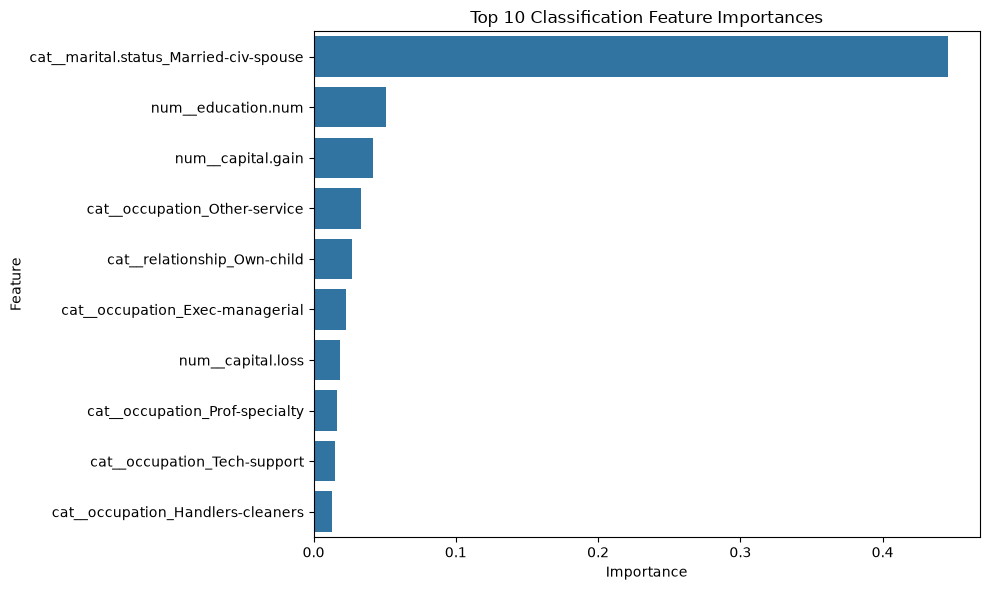

In [154]:
top_features = feature_importance.head(10)

plt.figure(figsize=(10,6))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title(
    "Top 10 Classification Feature Importances"
)

plt.tight_layout()

plt.savefig(
    "../results/figures/classification_feature_importance.png"
)

plt.show()


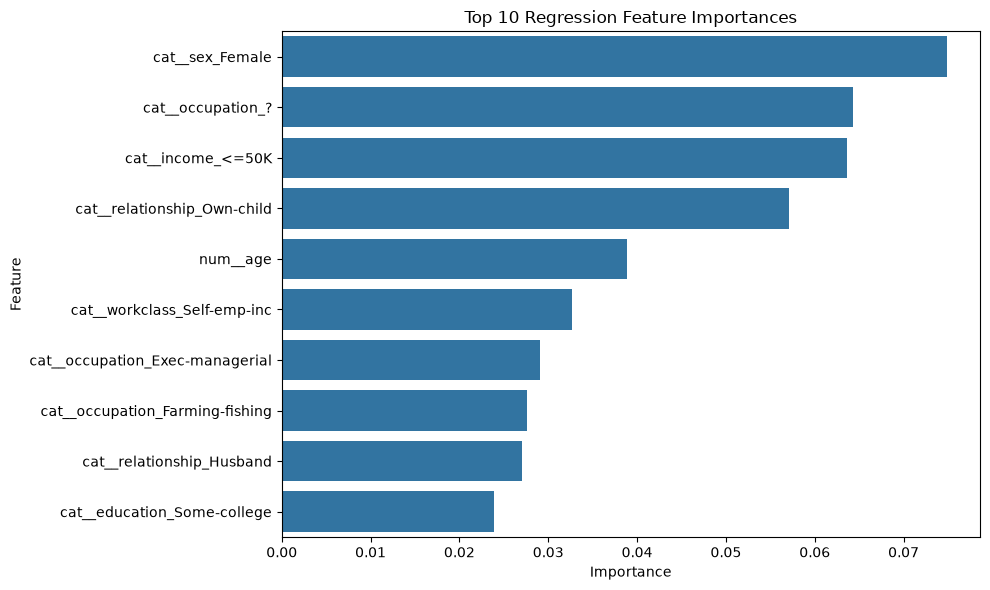

In [155]:
top_reg_features = reg_importance.head(10)

plt.figure(figsize=(10,6))

sns.barplot(
    data=top_reg_features,
    x="Importance",
    y="Feature"
)

plt.title(
    "Top 10 Regression Feature Importances"
)

plt.tight_layout()

plt.savefig(
    "../results/figures/regression_feature_importance.png"
)

plt.show()

Additional Validation

5-Fold Stratified Cross Validation (Classification)

In [165]:
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_score


In [166]:
stratified_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [168]:
'y_train_xgb' in globals()

True

5-Fold Stratified Cross Validation (Classification)

To assess model robustness we carried out 5-fold stratified cross-validation on the best performing classification model (XGBoost). The cross-validation was stratified so as to preserve the class distribution within each fold and give a more robust estimate of generalisation performance.



In [169]:
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_score

stratified_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    xgb_model,
    X_cls,
    y_cls.map({
        "<=50K": 0,
        ">50K": 1
    }),
    cv=stratified_cv,
    scoring="accuracy"
)

cv_scores


array([0.86964532, 0.872543  , 0.86993243, 0.87684275, 0.87453931])

In [170]:
print("Mean Accuracy: - ML_Project.ipynb:1")
print(cv_scores.mean())

print("\nStandard Deviation: - ML_Project.ipynb:4")
print(cv_scores.std())

Mean Accuracy: - ML_Project.ipynb:1
0.8727005637185277

Standard Deviation: - ML_Project.ipynb:4
0.0027408240004043252


Cross-Validation Results

Five-fold stratified cross-validation was carried out using the XGBoost classifier to assess the model's robustness and generalisation performance.

The model achieved a mean cross-validation accuracy of 87.27% (std dev 0.0027). The very low std dev indicates that performance was extremely consistent across all the folds, which is a good sign in terms of stability and generalisation.

These results further bolster the confidence that the XGBoost classifier is not going to be overly sensitive to any one particular train/test split and should therefore be reasonably robust on new data.



5-Fold Cross Validation (Regression)

Five fold cross validation was carried out on the best performing regression model (XGBoost Regressor) to assess predictive robustness and generalisation performance.



In [171]:
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

reg_cv_scores = cross_val_score(
    xgb_regressor,
    X_reg,
    y_reg,
    cv=kfold,
    scoring="r2"
)

reg_cv_scores

array([0.26727754, 0.29543197, 0.264943  , 0.27804559, 0.25929815])

In [172]:
print("Mean R²: - ML_Project.ipynb:1")
print(reg_cv_scores.mean())

print("\nStandard Deviation: - ML_Project.ipynb:4")
print(reg_cv_scores.std())

Mean R²: - ML_Project.ipynb:1
0.2729992508888245

Standard Deviation: - ML_Project.ipynb:4
0.012759733010461282


Regression Cross-Validation Results

Five fold cross validation was performed using the XGBoost Regressor to assess model robustness and generalisation performance.

The model achieved a mean R² of 0.273 (SD 0.0128). The very low SD indicates that performance was quite consistent across all the folds and so the model appears to generalise quite well.

The CV results back up the findings from the held out test set and provide further confidence that the model isn't overly reliant on any one particular train/test split.



In [175]:
import mlflow

c:\Users\alnoo\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


MLflow Experiment Tracking

This section records model training runs and evaluation results using MLflow for experiment tracking.

In [176]:
import mlflow

mlflow.set_experiment("Classification Models")

with mlflow.start_run(run_name="XGBoost_Classifier"):

    mlflow.log_metric("Accuracy", 0.8689)
    mlflow.log_metric("Precision", 0.7759)
    mlflow.log_metric("Recall", 0.6403)
    mlflow.log_metric("F1", 0.7016)

print("MLflow run completed - ML_Project.ipynb:12")

2026/11/10 21:40:01 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/10 21:40:01 INFO mlflow.store.db.utils: Updating database tables
2026/11/10 21:40:06 INFO mlflow.tracking.fluent: Experiment with name 'Classification Models' does not exist. Creating a new experiment.
2026/11/10 21:40:06 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - w

MLflow run completed - ML_Project.ipynb:12


In [177]:
with mlflow.start_run(run_name="Logistic_Regression"):

    mlflow.log_metric("Accuracy", 0.8531)
    mlflow.log_metric("Precision", 0.7392)
    mlflow.log_metric("Recall", 0.6020)
    mlflow.log_metric("F1", 0.6636)

print("Logistic Regression run completed - ML_Project.ipynb:8")

Logistic Regression run completed - ML_Project.ipynb:8


In [178]:
with mlflow.start_run(run_name="Random_Forest"):

    mlflow.log_metric("Accuracy", 0.8512)
    mlflow.log_metric("Precision", 0.7260)
    mlflow.log_metric("Recall", 0.6135)
    mlflow.log_metric("F1", 0.6651)

print("Random Forest run completed - ML_Project.ipynb:8")

Random Forest run completed - ML_Project.ipynb:8


In [179]:
mlflow.set_experiment("Regression Models")

with mlflow.start_run(run_name="XGBoost_Regressor"):

    mlflow.log_metric("MAE", 7.31)
    mlflow.log_metric("RMSE", 10.62)
    mlflow.log_metric("R2", 0.266)

print("XGBoost Regressor run completed - ML_Project.ipynb:9")

2026/11/10 21:41:39 INFO mlflow.tracking.fluent: Experiment with name 'Regression Models' does not exist. Creating a new experiment.


XGBoost Regressor run completed - ML_Project.ipynb:9


In [180]:
with mlflow.start_run(run_name="Ridge_Regression"):

    mlflow.log_metric("MAE", 7.78)
    mlflow.log_metric("RMSE", 11.12)
    mlflow.log_metric("R2", 0.196)

print("Ridge Regression run completed - ML_Project.ipynb:7")

Ridge Regression run completed - ML_Project.ipynb:7


In [181]:
with mlflow.start_run(run_name="Random_Forest_Regressor"):

    mlflow.log_metric("MAE", 7.75)
    mlflow.log_metric("RMSE", 11.18)
    mlflow.log_metric("R2", 0.188)

print("Random Forest Regressor run completed - ML_Project.ipynb:7")


Random Forest Regressor run completed - ML_Project.ipynb:7
